# Online Retail Sales Analysis

An exploratory analysis of the UCI Online Retail transaction dataset, covering **1 December 2010 to 9 December 2011**. This notebook separates positive sales from returns and other adjustments so the revenue trend has a clear, consistent definition.

## Questions

- How did sales revenue change month to month?
- Which countries and products contributed the most recorded sales revenue?
- How common were repeat purchases among identifiable customers?
- What caveats should guide interpretation?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Works when launched from the project root or the notebooks directory.
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "Online Retail.xlsx"
CHARTS_DIR = ROOT / "reports" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_excel(DATA_PATH)
print(f"Raw data: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print(f"Date range: {raw['InvoiceDate'].min()} — {raw['InvoiceDate'].max()}")
raw.head()

Raw data: 541,909 rows × 8 columns
Date range: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Prepare the analysis data

Remove exact duplicate rows, then define a sales row as a positive quantity, positive unit price, and invoice number that does not begin with `C`. This excludes returns/cancellations and zero-value records from sales metrics. Missing customer IDs remain in sales totals but are omitted from customer-level analysis.

In [2]:
df = raw.drop_duplicates().copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

sales = df.loc[
    (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")

summary = pd.Series({
    "Sales rows": len(sales),
    "Invoices with sales": sales["InvoiceNo"].nunique(),
    "Identifiable customers": sales["CustomerID"].nunique(),
    "Recorded sales revenue (£)": sales["Revenue"].sum(),
})
print(summary.to_string())

Sales rows                    5.248780e+05
Invoices with sales           1.996000e+04
Identifiable customers        4.338000e+03
Recorded sales revenue (£)    1.064211e+07


## Monthly revenue

Revenue is the sum of quantity × unit price for the sales rows defined above. December 2011 is partial: the dataset ends on 9 December, so it is not directly comparable with full months.

In [3]:
monthly_revenue = sales.groupby("Month")["Revenue"].sum()
monthly_revenue.round(2)

Month
2010-12     821452.73
2011-01     689811.61
2011-02     522545.56
2011-03     716215.26
2011-04     536968.49
2011-05     769296.61
2011-06     760547.01
2011-07     718076.12
2011-08     757841.38
2011-09    1056435.19
2011-10    1151263.73
2011-11    1503866.78
2011-12     637790.33
Freq: M, Name: Revenue, dtype: float64

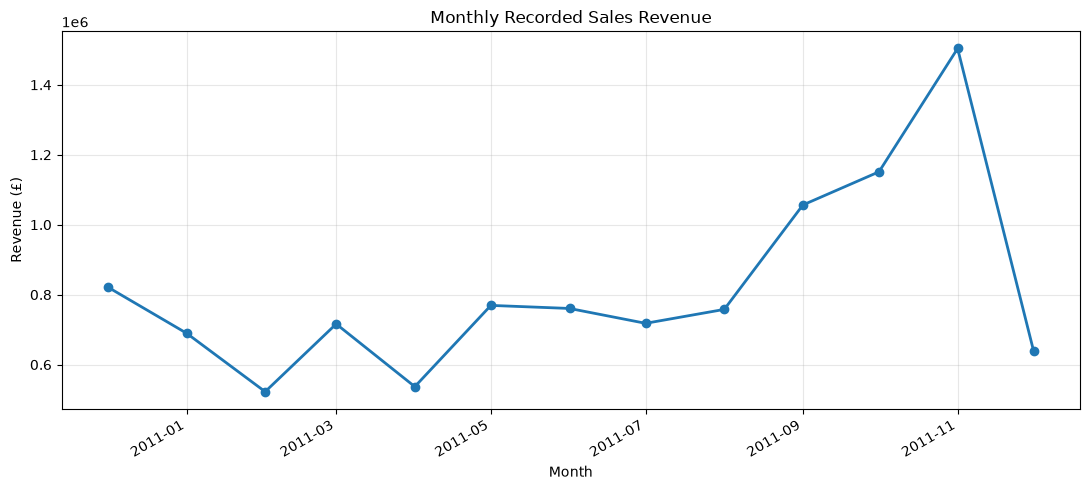

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_revenue.index.to_timestamp(), monthly_revenue.values, marker="o", linewidth=2)
ax.set(title="Monthly Recorded Sales Revenue", xlabel="Month", ylabel="Revenue (£)")
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(CHARTS_DIR / "monthly_revenue.png", dpi=160, bbox_inches="tight")
plt.show()

Revenue rose through autumn, reaching its highest complete month in **November 2011 (£1.50m)**. December shows **£637.8k** but covers only 1–9 December. Monthly totals can also be affected by seasonality and the dataset’s limited 13-month window.

## Country and product contribution

In [5]:
country_revenue = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = country_revenue.get("United Kingdom", 0) / sales["Revenue"].sum() * 100
print(f"UK share of recorded sales revenue: {uk_share:.1f}%")
country_revenue.head(10).round(2)

UK share of recorded sales revenue: 84.6%


Country
United Kingdom    9001744.09
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Australia          138453.81
Spain               61558.56
Switzerland         57067.60
Belgium             41196.34
Sweden              38367.83
Name: Revenue, dtype: float64

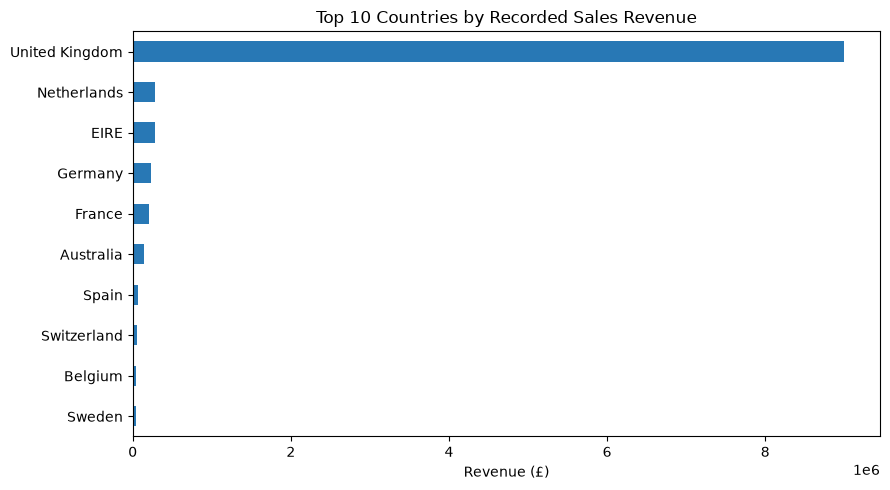

In [6]:
top_countries = country_revenue.head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
top_countries.plot(kind="barh", ax=ax, color="#2878B5")
ax.set(title="Top 10 Countries by Recorded Sales Revenue", xlabel="Revenue (£)", ylabel="")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "top_10_countries.png", dpi=160, bbox_inches="tight")
plt.show()

In [7]:
product_revenue = sales.groupby("Description")["Revenue"].sum().sort_values(ascending=False)
product_revenue.head(10).round(2)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

Product rankings use transaction descriptions as provided; the source may include postage or other non-merchandise descriptions. Review descriptions before treating the ranking as a pure physical-product leaderboard.

## Customer purchasing patterns

In [8]:
identified = sales.loc[sales["CustomerID"].notna()]
orders_per_customer = identified.groupby("CustomerID")["InvoiceNo"].nunique()
repeat_rate = orders_per_customer.gt(1).mean() * 100
print(f"Customers with an ID: {len(orders_per_customer):,}")
print(f"Customers with multiple invoices: {orders_per_customer.gt(1).sum():,}")
print(f"Repeat-customer rate: {repeat_rate:.1f}%")
print("\nTop 10 identified customers by recorded sales revenue:")
identified.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10).round(2)

Customers with an ID: 4,338
Customers with multiple invoices: 2,845
Repeat-customer rate: 65.6%

Top 10 identified customers by recorded sales revenue:


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

## Findings and recommendations

1. **Plan for UK concentration.** The UK accounts for about 84.6% of recorded sales revenue in this sales-only view. Track other markets separately before committing inventory or marketing spend.
2. **Investigate the autumn peak.** September–November sales increased; compare with prior-year data and campaign/calendar records before attributing the rise to a cause.
3. **Use customer-level analysis carefully.** Repeat purchasing is measurable for customers with IDs only; anonymous transactions are excluded, so the rate is not representative of every buyer.
4. **Reconcile sales and adjustments.** Returns and cancellations were excluded from the headline sales trend. Pair this report with a separate returns analysis for net financial performance.
5. **Treat this as descriptive analysis.** It summarizes observed transactions and does not establish causation or forecast future performance.

## Limitations

- The dataset spans only about one year and ends partway through December 2011.
- Recorded revenue is transaction line quantity × unit price; taxes, shipping treatment, and accounting adjustments are not independently reconciled.
- Missing customer IDs prevent full customer-level coverage.
- Country totals reflect the dataset labels and should not be treated as market size estimates.

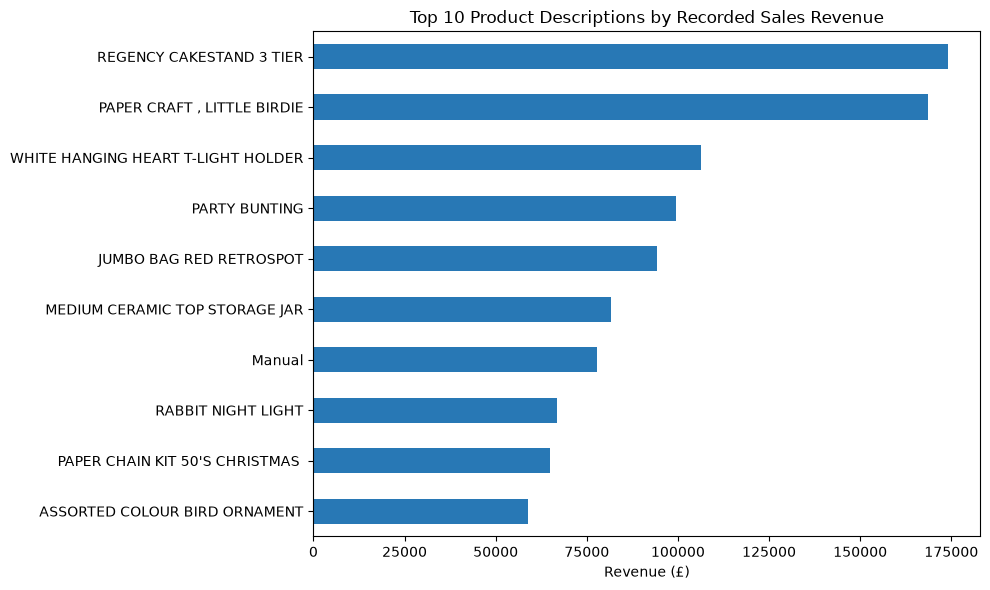

Updated monthly summary and top products chart.


In [9]:
# Save a monthly summary using the notebook's sales-only data
monthly_report = (
    sales.groupby("Month")
    .agg(
        Revenue=("Revenue", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
    )
)

monthly_report["Revenue_Change_%"] = (
    monthly_report["Revenue"].pct_change() * 100
)

monthly_report.to_csv(ROOT / "reports" / "monthly_revenue_summary.csv")

# Create a top 10 physical products chart, excluding postage
physical_product_revenue = product_revenue.drop(
    index=["POSTAGE", "DOTCOM POSTAGE"],
    errors="ignore",
)

top_products = physical_product_revenue.nlargest(10).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
top_products.plot(kind="barh", ax=ax, color="#2878B5")
ax.set(
    title="Top 10 Product Descriptions by Recorded Sales Revenue",
    xlabel="Revenue (£)",
    ylabel="",
)
fig.tight_layout()
fig.savefig(
    CHARTS_DIR / "top_10_products.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Updated monthly summary and top products chart.")
